# **Retrieval Evaluation with LangGraph**

![Retrieval Evaluator RAG Pipeline.png](<attachment:Retrieval Evaluator RAG Pipeline.png>)
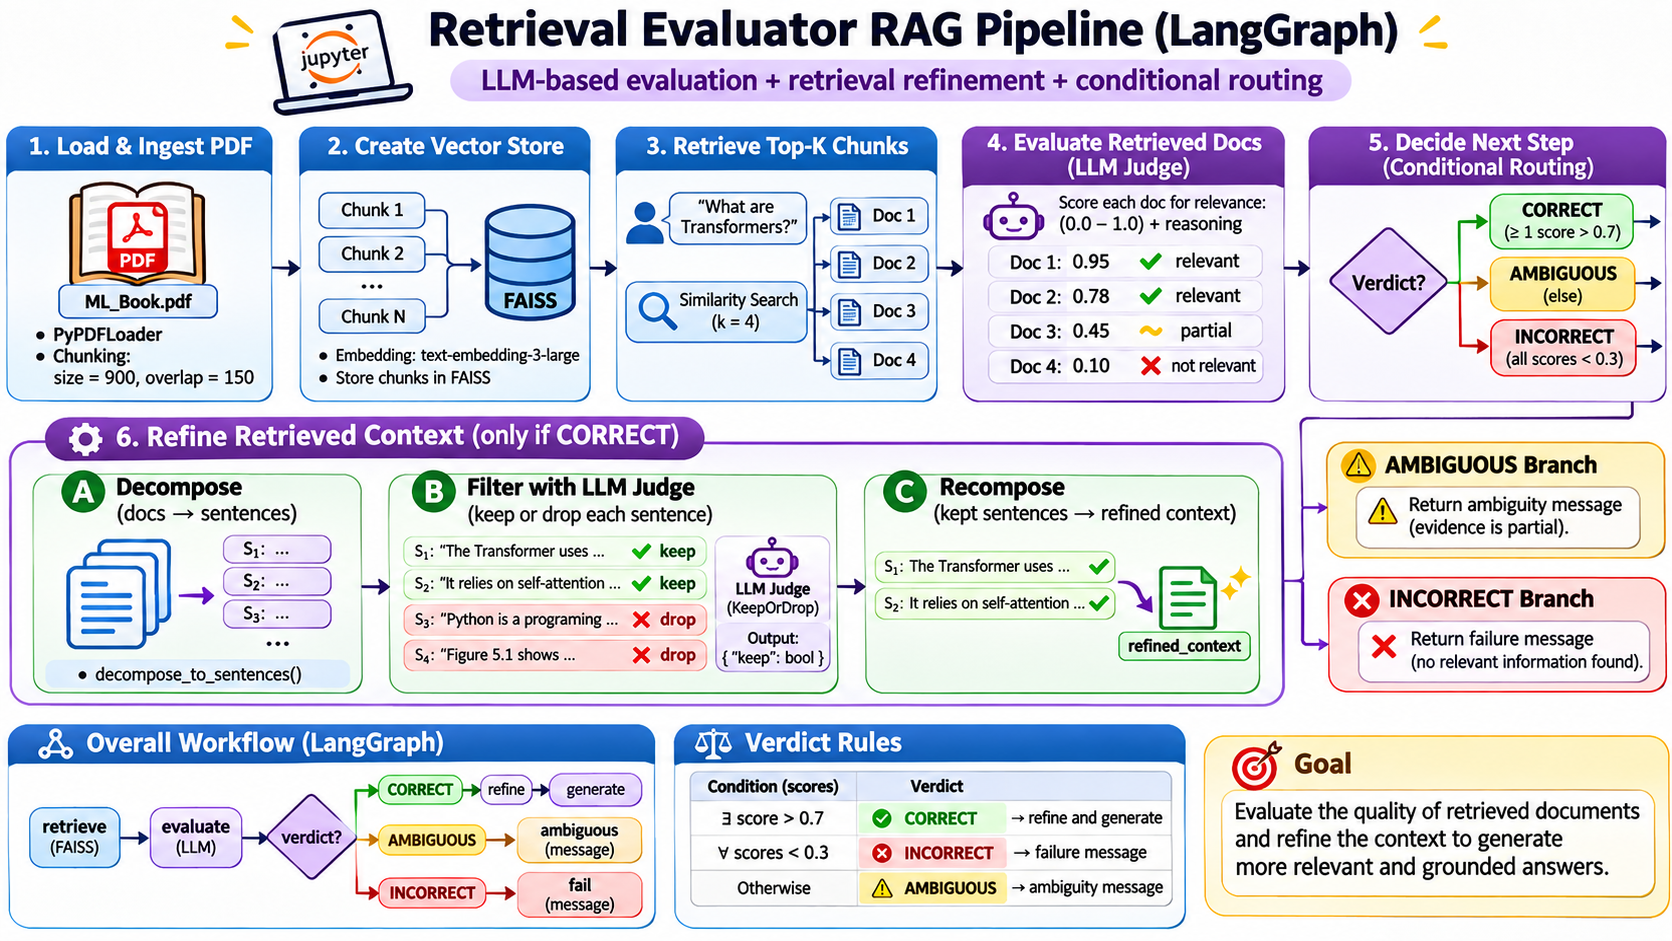

This notebook extends basic RAG by introducing an **LLM-based document evaluator** before answer generation. Instead of trusting every retrieved document, the system scores its relevance and decides the next action.

### 1. Retrieval

- Load `ML Book.pdf` using `PyPDFLoader`.
- Split documents into chunks (size = 900, overlap = 150).
- Generate embeddings using `text-embedding-3-large`.
- Store embeddings in FAISS and retrieve the top 4 relevant chunks.

### 2. Document Evaluation (LLM Judge)

Each retrieved chunk is evaluated using `gpt-4o-mini`, returning structured output:

```python
class DocEvalScore(BaseModel):
    score: float
    reason: str
```

The LLM assigns a relevance score between 0 and 1, along with an explanation.

### 3. Conditional Routing

The evaluator determines the next step using two thresholds:

| Verdict | Condition | Action |
|---|---|---|
| CORRECT | Any score > 0.7 | Refine and generate |
| INCORRECT | All scores < 0.3 | Return failure message |
| AMBIGUOUS | Otherwise | Return ambiguity message |

For the **CORRECT** branch, only chunks with scores > 0.3 are retained.

### 4. Retrieval Refinement

Accepted documents undergo three stages:

1. **Decompose:** Split retrieved text into individual sentences.
2. **Filter:** Use an LLM judge to keep or discard each sentence based on relevance.
3. **Recompose:** Combine the accepted sentences into `refined_context`.

### 5. Answer Generation

The final LLM generates an answer using only the refined context. If sufficient information is unavailable, it should respond with `"I don't know"`.

### 6. LangGraph Workflow

```text
START → Retrieve → Evaluate
                      │
             ┌────────┼────────┐
             ▼        ▼        ▼
          CORRECT  AMBIGUOUS  INCORRECT
             │        │        │
           Refine   Message   Failure
             │        │        │
          Generate    END      END
             │
            END
```

**Key takeaway:** This pipeline combines document-level evaluation with sentence-level refinement, improving control over which retrieved information reaches the final LLM.

**Limitation:** The INCORRECT branch currently returns a failure message rather than performing web search or retrying retrieval. Those capabilities can be added in a more complete Corrective RAG implementation.

In [8]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel
import re

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

In [3]:
docs = (
    PyPDFLoader("./documents/ML Book.pdf").load()
)

In [4]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [5]:
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

from langchain_huggingface import HuggingFaceEmbeddings

hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, hf_embeddings)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [6]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [7]:
UPPER_TH = 0.7
LOWER_TH = 0.3

In [9]:
class State(TypedDict):
    question: str
    docs: List[Document]

    good_docs: List[Document]
    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str
    
    answer: str

In [10]:
def retrieve_node(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [ ]:
# -----------------------------
# Score-based doc evaluator
# -----------------------------
class DocEvalScore(BaseModel):
    score: float
    reason: str

doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

doc_eval_chain = doc_eval_prompt | llm.with_structured_output(DocEvalScore)


In [ ]:
# Test the doc_eval_chain with a sample question and chunks

question = "What is the bias-variance tradeoff in machine learning?"

test_chunks = [
    # Highly relevant
    "The bias-variance tradeoff describes the balance between "
    "underfitting and overfitting. High bias leads to underfitting, "
    "while high variance leads to overfitting. The goal is to "
    "minimize prediction error by balancing both.",

    # Relevant but incomplete
    "Bias refers to systematic errors caused by overly simple models. "
    "High-bias models often underfit training data.",

    # Related concept
    "Regularization techniques such as L1 and L2 help prevent "
    "overfitting by penalizing model complexity.",

    # General machine learning
    "Machine learning algorithms learn patterns from data and "
    "make predictions on unseen examples.",

    # Irrelevant topic
    "The Large Hadron Collider accelerates protons to high energies "
    "to study fundamental particles.",

    # Another irrelevant topic
    "Python is a widely used programming language for data science "
    "and web development."
]

import pandas as pd

results = []

for i, chunk in enumerate(test_chunks, start=1):

    evaluation = doc_eval_chain.invoke({
        "question": question,
        "chunk": chunk
    })

    results.append({
        "Chunk": f"Chunk {i}",
        "Text": chunk,
        "Score": evaluation.score,
        "Reason": evaluation.reason
    })

df = pd.DataFrame(results)

display(df)

,Chunk,Text,Score,Reason
0,Chunk 1,The bias-variance tradeoff describes the balan...,1.0,The chunk provides a clear and concise explana...
1,Chunk 2,Bias refers to systematic errors caused by ove...,0.5,The chunk provides information about bias in m...
2,Chunk 3,Regularization techniques such as L1 and L2 he...,0.0,The chunk discusses regularization techniques ...
3,Chunk 4,Machine learning algorithms learn patterns fro...,0.0,The chunk does not provide any information abo...
4,Chunk 5,The Large Hadron Collider accelerates protons ...,0.0,The chunk is completely irrelevant to the ques...
5,Chunk 6,Python is a widely used programming language f...,0.0,The chunk does not address the bias-variance t...


In [13]:
def eval_each_doc_node(state: State) -> State:

    q = state["question"]
    
    scores: List[float] = []
    reasons: List[str] = []
    good: List[Document] = []

    for d in state["docs"]:
        out = doc_eval_chain.invoke({"question": q, "chunk": d.page_content})
        scores.append(out.score)
        reasons.append(out.reason)

        # 1) for CORRECT case we will refine only docs with score > LOWER_TH
        if out.score > LOWER_TH:
            good.append(d)

    # 2) CORRECT if at least one doc > UPPER_TH
    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }

    # 3) INCORRECT if all docs < LOWER_TH
    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}. {why}",
        }

    # 4) Anything in between => AMBIGUOUS
    why = "Mixed relevance signals."
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. {why}",
    }


In [14]:
# -----------------------------
# Sentence-level DECOMPOSER
# -----------------------------
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

# -----------------------------
# FILTER (LLM judge)
# -----------------------------
class KeepOrDrop(BaseModel):
    keep: bool

filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)

# -----------------------------
# REFINING (Decompose -> Filter -> Recompose)
# -----------------------------
def refine(state: State) -> State:
    q = state["question"]

    # Combine retrieved docs into one context string
    # 5) In CORRECT case, eval node populates good_docs with docs having score > LOWER_TH
    context = "\n\n".join(d.page_content for d in state["good_docs"]).strip()

    # 1) DECOMPOSITION: context -> sentence strips
    strips = decompose_to_sentences(context)

    # 2) FILTER: keep only relevant strips
    kept: List[str] = []
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    # 3) RECOMPOSE: glue kept strips back together (internal knowledge)
    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }


In [15]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    out = (answer_prompt | llm).invoke(
        {"question": state["question"], "refined_context": state["refined_context"]}
    )
    return {"answer": out.content}


In [16]:
def fail_node(state: State) -> State:
    return {"answer": f"FAIL: {state['reason']}"}

def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}

def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    elif state["verdict"] == "INCORRECT":
        return "web_search"
    else:
        return "ambiguous"


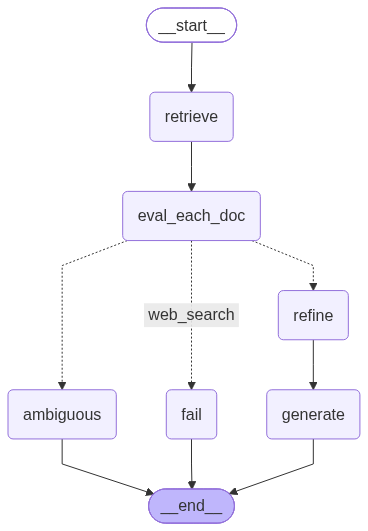

In [17]:
g = StateGraph(State)
g.add_node("retrieve", retrieve_node)
g.add_node("eval_each_doc", eval_each_doc_node)
g.add_node("refine", refine)
g.add_node("generate", generate)
g.add_node("fail", fail_node)
g.add_node("ambiguous", ambiguous_node)


g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,
    {"refine": "refine", "web_search": "fail", "ambiguous": "ambiguous"}
)
g.add_edge("refine", "generate")
g.add_edge("generate", END)
g.add_edge("fail", END)

app = g.compile()
app


In [18]:
res = app.invoke(
    {
        "question": "What are Transformers & why they important ",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res["answer"])


VERDICT: INCORRECT
REASON: All retrieved chunks scored < 0.3. No chunk was sufficient.

OUTPUT:
 FAIL: All retrieved chunks scored < 0.3. No chunk was sufficient.


In [19]:
res = app.invoke(
    {
        "question": "Explain the bias–variance tradeoff",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res["answer"])


VERDICT: CORRECT
REASON: At least one retrieved chunk scored > 0.7.

OUTPUT:
 The bias–variance tradeoff is a fundamental concept in statistics and machine learning that describes the relationship between a model's complexity and its generalization error. It states that a model's generalization error can be decomposed into three components: bias, variance, and irreducible error.

- **Bias** refers to the error introduced by approximating a real-world problem, which may be complex, with a simplified model. High-bias models make strong assumptions about the data (e.g., assuming linearity when the relationship is actually quadratic), leading to underfitting the training data.

- **Variance** is the error due to the model's sensitivity to small fluctuations in the training data. Models with high variance are overly complex and can capture noise in the training data, leading to overfitting.

The tradeoff is that as you decrease bias by making the model more complex, variance tends to increa

In [ ]:
# Bias variance tradeoff
# AI news from last week
# What are attention mechanisms and why are they important in current models?